In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
model_path = "../saved_models/best_resnet50.keras"

resnet_model = tf.keras.models.load_model(
    model_path
)

print("ResNet50 model loaded successfully!")
print("Input shape:", resnet_model.input_shape)
print("Output shape:", resnet_model.output_shape)

ResNet50 model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 5)


In [3]:
import sys

project_root = os.path.abspath("../..")
preprocessing_dir = os.path.join(
    project_root,
    "ml-model",
    "preprocessing"
)

if preprocessing_dir not in sys.path:
    sys.path.insert(0, preprocessing_dir)

import dataset_loader

In [4]:
csv_path = r"D:\AI-Powered-Diabetic-Retinopathy-System\ml-model\dataset\raw\train.csv"

image_dir = r"D:\AI-Powered-Diabetic-Retinopathy-System\ml-model\dataset\raw\train_images"

df = dataset_loader.load_metadata(csv_path)

df = dataset_loader.create_image_paths(
    df,
    image_dir
)

df = dataset_loader.validate_image_paths(df)

train_df, validation_df, test_df = dataset_loader.split_dataset(
    df,
    test_size=0.15,
    validation_size=0.15,
    random_state=42
)

print("Train:", len(train_df))
print("Validation:", len(validation_df))
print("Test:", len(test_df))

Train: 2563
Validation: 549
Test: 550


In [5]:
test_dataset = dataset_loader.create_tf_dataset(
    test_df,
    batch_size=8,
    shuffle=False,
    training=False
)

print("Test dataset created successfully!")

Test dataset created successfully!


In [6]:
y_true = []
y_pred = []
y_prob = []

for images, labels in test_dataset:

    predictions = resnet_model.predict(
        images,
        verbose=0
    )

    y_true.extend(
        labels.numpy()
    )

    y_pred.extend(
        np.argmax(predictions, axis=1)
    )

    y_prob.extend(
        predictions
    )

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

print("Predictions generated successfully!")
print("Number of test samples:", len(y_true))

Predictions generated successfully!
Number of test samples: 550


In [7]:
class_names = [
    "No DR",
    "Mild DR",
    "Moderate DR",
    "Severe DR",
    "Proliferative DR"
]

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print("Final ResNet50 Classification Report")
print("---------------------------------------")
print(report)

Final ResNet50 Classification Report
---------------------------------------
                  precision    recall  f1-score   support

           No DR     0.9527    0.9668    0.9597       271
         Mild DR     0.4737    0.6429    0.5455        56
     Moderate DR     0.7456    0.5667    0.6439       150
       Severe DR     0.4286    0.3103    0.3600        29
Proliferative DR     0.3750    0.5455    0.4444        44

        accuracy                         0.7564       550
       macro avg     0.5951    0.6064    0.5907       550
    weighted avg     0.7736    0.7564    0.7586       550



In [8]:
cm = confusion_matrix(
    y_true,
    y_pred
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[262   7   2   0   0]
 [  5  36  11   0   4]
 [  7  29  85   8  21]
 [  0   0   5   9  15]
 [  1   4  11   4  24]]


<Figure size 800x700 with 0 Axes>

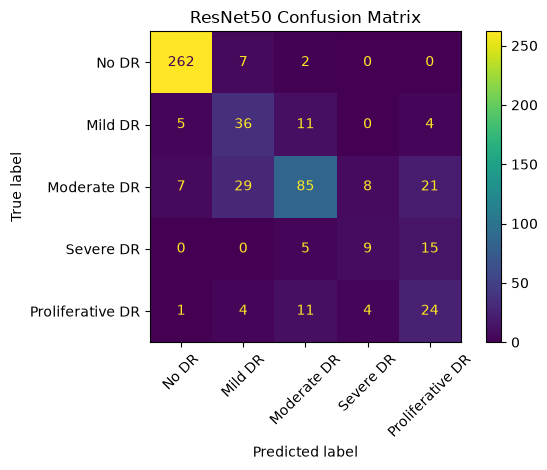

In [9]:
plt.figure(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    values_format="d",
    xticks_rotation=45
)

plt.title("ResNet50 Confusion Matrix")
plt.tight_layout()
plt.show()

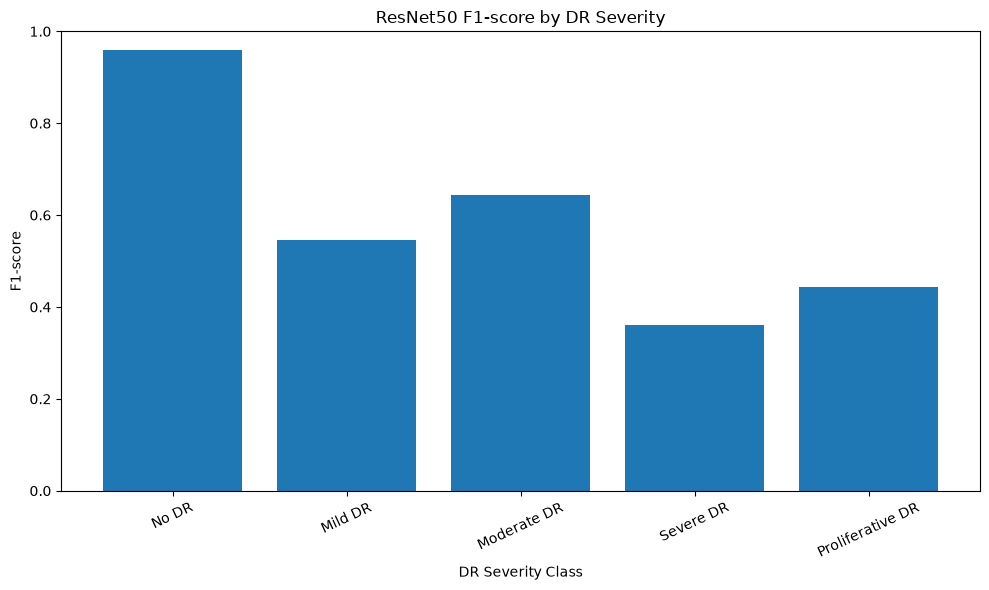

In [10]:
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    zero_division=0
)

plt.figure(figsize=(10, 6))

plt.bar(
    class_names,
    f1
)

plt.ylabel("F1-score")
plt.xlabel("DR Severity Class")
plt.title("ResNet50 F1-score by DR Severity")
plt.ylim(0, 1)

plt.xticks(
    rotation=25
)

plt.tight_layout()
plt.show()

In [11]:
class_counts = train_df["diagnosis"].value_counts().sort_index()

class_names = [
    "No DR",
    "Mild DR",
    "Moderate DR",
    "Severe DR",
    "Proliferative DR"
]

print("Training Class Distribution")
print("----------------------------")

for class_id, count in class_counts.items():
    print(
        f"{class_id} - {class_names[class_id]}: {count}"
    )

Training Class Distribution
----------------------------
0 - No DR: 1263
1 - Mild DR: 259
2 - Moderate DR: 699
3 - Severe DR: 135
4 - Proliferative DR: 207


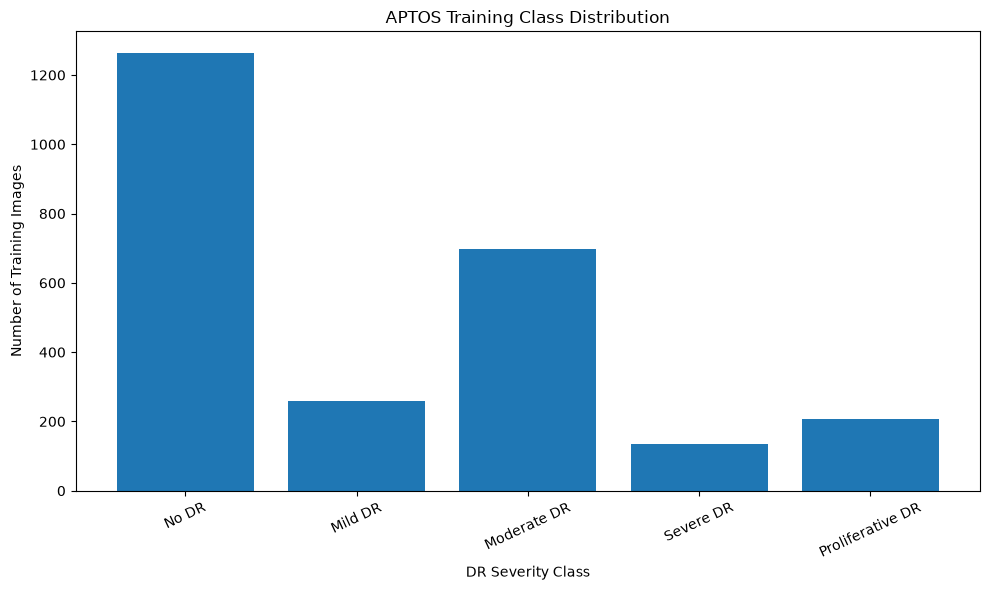

In [12]:
plt.figure(figsize=(10, 6))

plt.bar(
    class_names,
    class_counts.values
)

plt.xlabel("DR Severity Class")
plt.ylabel("Number of Training Images")
plt.title("APTOS Training Class Distribution")

plt.xticks(rotation=25)

plt.tight_layout()
plt.show()